In [2]:
%pip install opencv-python numpy matplotlib


Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\shash\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("All libraries imported successfully!")
print("Notebook directory:", Path.cwd())

OpenCV version: 5.0.0
NumPy version: 2.4.3
All libraries imported successfully!
Notebook directory: c:\Users\shash\OneDrive\Desktop\SEMESTER05\DSIP(01CT0513)\Python DSIP\OPE 9


In [ ]:
#Importing libraries
import os
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("Notebook working directory:", Path.cwd())

OpenCV version: 5.0.0
Notebook working directory: c:\Users\shash\OneDrive\Desktop\SEMESTER05\DSIP(01CT0513)\Python DSIP\OPE 9


In [ ]:
IMAGE_FILES = {
    "face": "face.jpg",
    "xray": "xray.jpg",
    "city": "city.jpg",
    "building": "building.jpg",
    "motion": "motion.jpg",
}

print("Checking input images...")
missing = []
for name, filename in IMAGE_FILES.items():
    if Path(filename).is_file():
        print(f"✓ Found: {filename}")
    else:
        print(f"✗ Missing: {filename}")
        missing.append(filename)

if missing:
    print("\nExtract OEP9_input_images.zip and copy the missing files beside this notebook.")
else:
    print("\nAll five images are ready.")

Checking input images...
✓ Found: face.jpg
✓ Found: xray.jpg
✓ Found: city.jpg
✓ Found: building.jpg
✓ Found: motion.jpg

All five images are ready.


In [ ]:
INPUT_DIR = Path(".")  #this will Change if the five images are in a different folder
OUTPUT_DIR = Path("OEP9_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input folder:", INPUT_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

Input folder: C:\Users\shash\OneDrive\Desktop\SEMESTER05\DSIP(01CT0513)\Python DSIP\OPE 9
Output folder: C:\Users\shash\OneDrive\Desktop\SEMESTER05\DSIP(01CT0513)\Python DSIP\OPE 9\OEP9_Results


In [ ]:
def read_grayscale_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(
            f"Could not read '{path}'. Check the filename and INPUT_DIR."
        )
    return image


def save_image(filename, image):
    destination = OUTPUT_DIR / filename
    if not cv2.imwrite(str(destination), image):
        raise OSError(f"Could not save image to: {destination}")
    return destination


def show_comparison(images, titles, figure_title, save_path, columns=3):
    rows = int(np.ceil(len(images) / columns))
    plt.figure(figsize=(5 * columns, 4 * rows))

    for index, (image, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(rows, columns, index)
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")

    plt.suptitle(figure_title, fontsize=16)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved comparison:", save_path)

In [ ]:
def process_image(image_key, image_filename):
    input_path = INPUT_DIR / image_filename
    print("\n" + "=" * 60)
    print(f"Processing: {image_key} ({input_path})")
    print("=" * 60)

    original = read_grayscale_image(input_path)

    # Smoothing filters
    mean_img = cv2.blur(original, (5, 5))
    gaussian_img = cv2.GaussianBlur(original, (5, 5), 0)
    median_img = cv2.medianBlur(original, 5)
    bilateral_img = cv2.bilateralFilter(original, d=9, sigmaColor=75, sigmaSpace=75)

    # Laplacian-based sharpening
    laplacian = cv2.Laplacian(original, cv2.CV_32F, ksize=3)
    laplacian_sharp = np.clip(
        original.astype(np.float32) - 0.5 * laplacian, 0, 255
    ).astype(np.uint8)

    # Unsharp masking
    blurred = cv2.GaussianBlur(original, (5, 5), 0)
    unsharp = cv2.addWeighted(original, 1.5, blurred, -0.5, 0)

    results = {
        "original": original,
        "mean": mean_img,
        "gaussian": gaussian_img,
        "median": median_img,
        "bilateral": bilateral_img,
        "laplacian_sharpened": laplacian_sharp,
        "unsharp": unsharp,
    }

    # Save individual images
    for filter_name, result in results.items():
        print("Saved:", save_image(f"{image_key}_{filter_name}.png", result))

    # Smoothing comparison
    show_comparison(
        [original, mean_img, gaussian_img, median_img, bilateral_img],
        ["Original", "Mean Filter", "Gaussian Filter", "Median Filter", "Bilateral Filter"],
        f"{image_key.upper()} — Smoothing Comparison",
        OUTPUT_DIR / f"{image_key}_smoothing_comparison.png",
        columns=3,
    )

    # Sharpening comparison
    show_comparison(
        [original, laplacian_sharp, unsharp],
        ["Original", "Laplacian-based Sharpening", "Unsharp Masking"],
        f"{image_key.upper()} — Sharpening Comparison",
        OUTPUT_DIR / f"{image_key}_sharpening_comparison.png",
        columns=3,
    )

    return results


Processing: face (face.jpg)
Saved: OEP9_Results\face_original.png
Saved: OEP9_Results\face_mean.png
Saved: OEP9_Results\face_gaussian.png
Saved: OEP9_Results\face_median.png
Saved: OEP9_Results\face_bilateral.png
Saved: OEP9_Results\face_laplacian_sharpened.png
Saved: OEP9_Results\face_unsharp.png


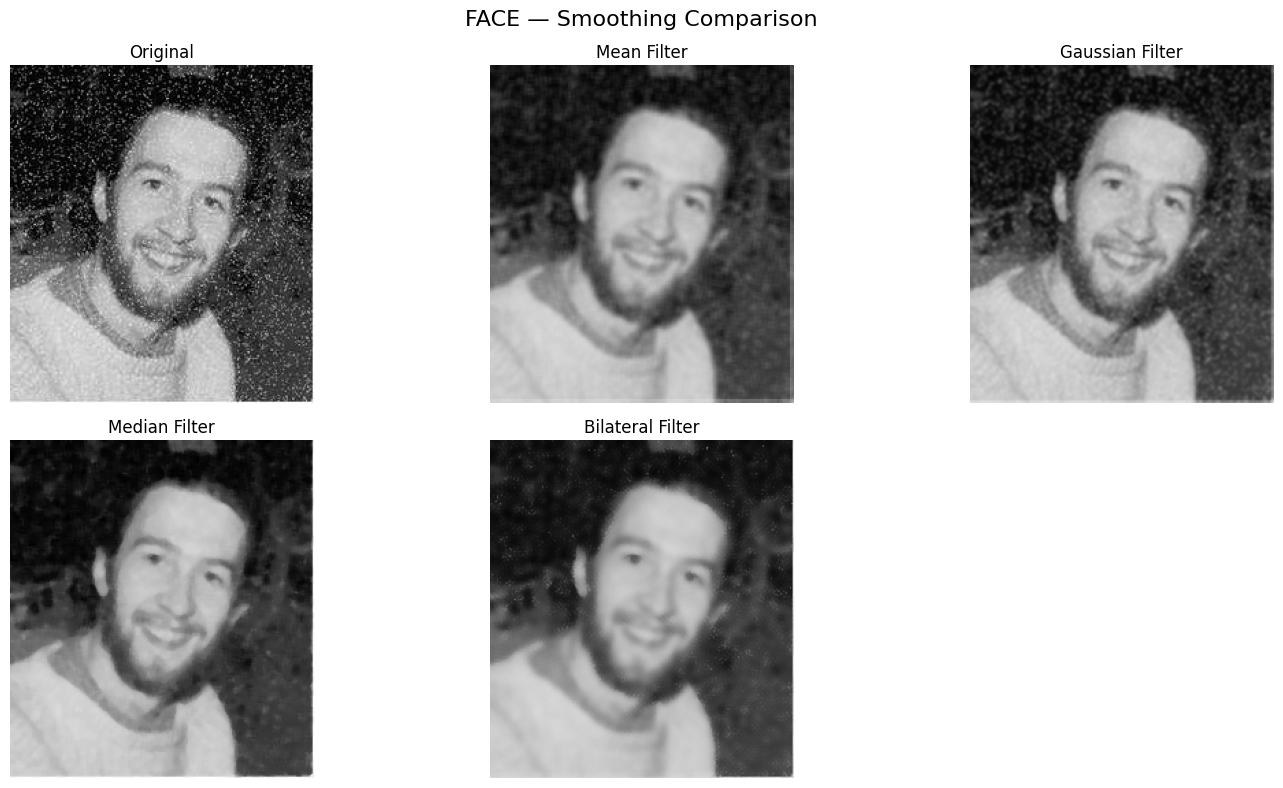

Saved comparison: OEP9_Results\face_smoothing_comparison.png


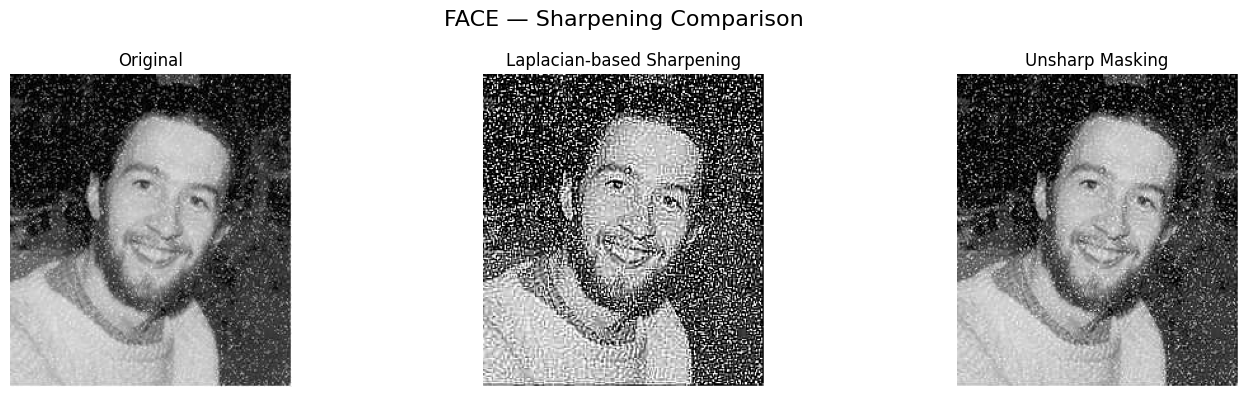

Saved comparison: OEP9_Results\face_sharpening_comparison.png

Processing: xray (xray.jpg)
Saved: OEP9_Results\xray_original.png
Saved: OEP9_Results\xray_mean.png
Saved: OEP9_Results\xray_gaussian.png
Saved: OEP9_Results\xray_median.png
Saved: OEP9_Results\xray_bilateral.png
Saved: OEP9_Results\xray_laplacian_sharpened.png
Saved: OEP9_Results\xray_unsharp.png


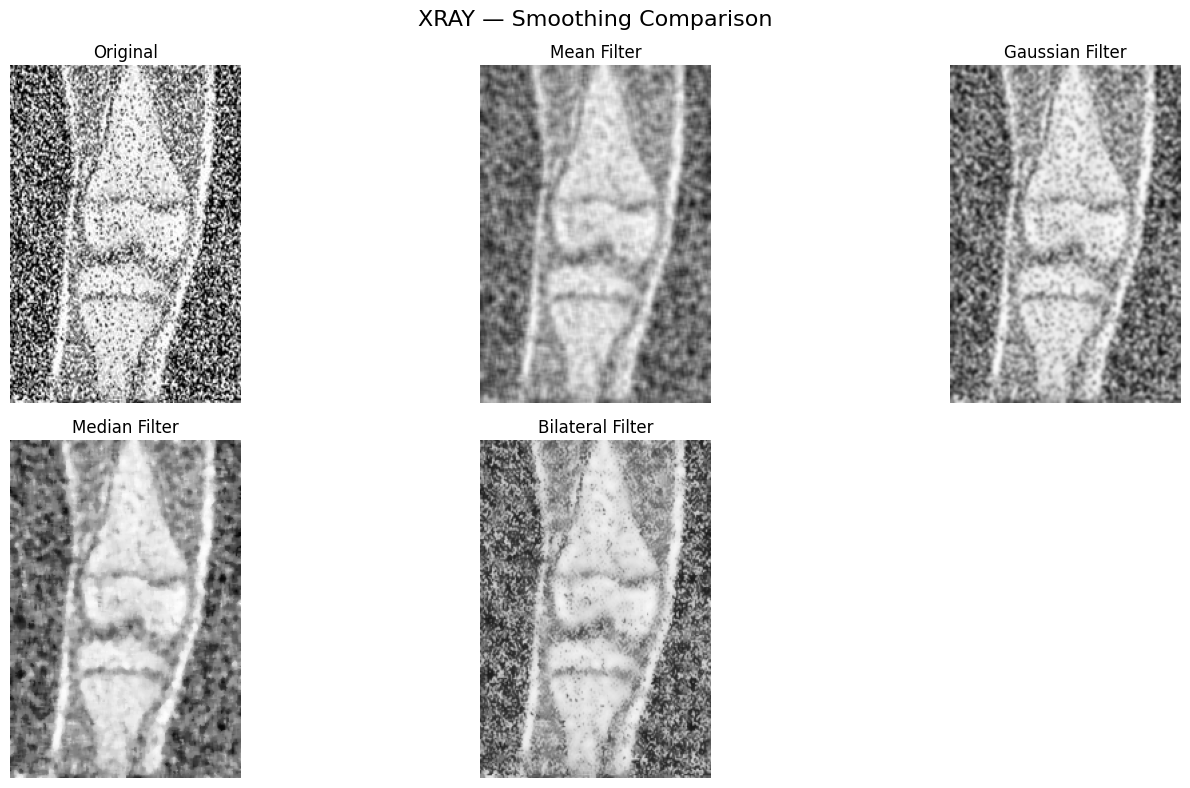

Saved comparison: OEP9_Results\xray_smoothing_comparison.png


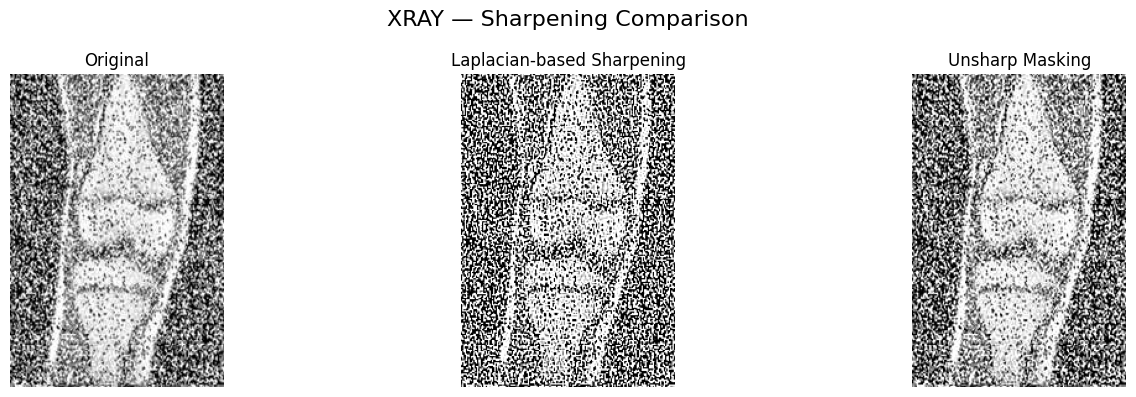

Saved comparison: OEP9_Results\xray_sharpening_comparison.png

Processing: city (city.jpg)
Saved: OEP9_Results\city_original.png
Saved: OEP9_Results\city_mean.png
Saved: OEP9_Results\city_gaussian.png
Saved: OEP9_Results\city_median.png
Saved: OEP9_Results\city_bilateral.png
Saved: OEP9_Results\city_laplacian_sharpened.png
Saved: OEP9_Results\city_unsharp.png


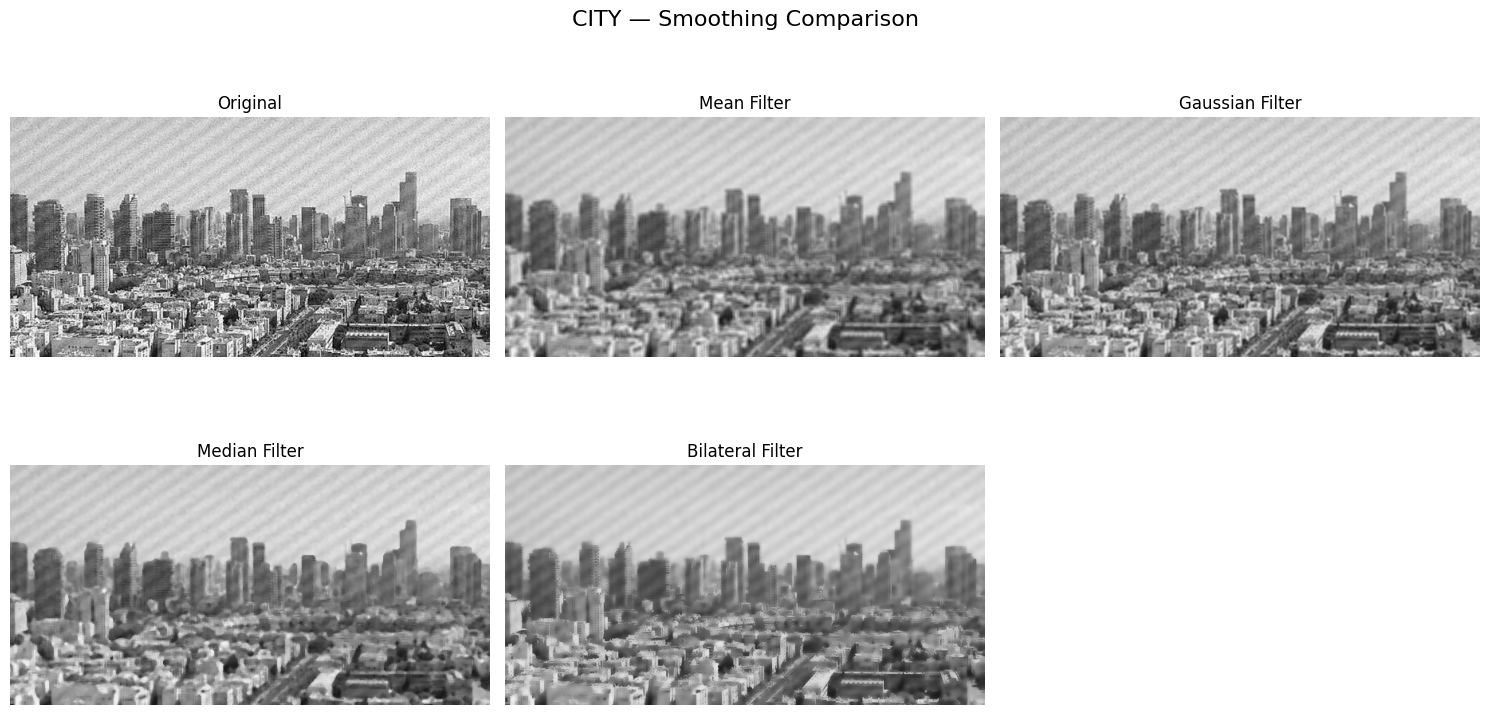

Saved comparison: OEP9_Results\city_smoothing_comparison.png


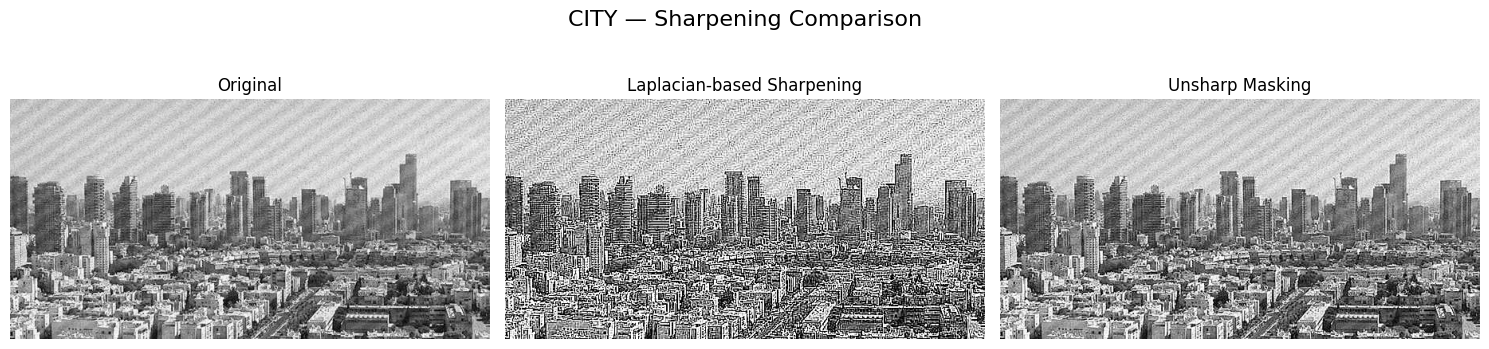

Saved comparison: OEP9_Results\city_sharpening_comparison.png

Processing: building (building.jpg)
Saved: OEP9_Results\building_original.png
Saved: OEP9_Results\building_mean.png
Saved: OEP9_Results\building_gaussian.png
Saved: OEP9_Results\building_median.png
Saved: OEP9_Results\building_bilateral.png
Saved: OEP9_Results\building_laplacian_sharpened.png
Saved: OEP9_Results\building_unsharp.png


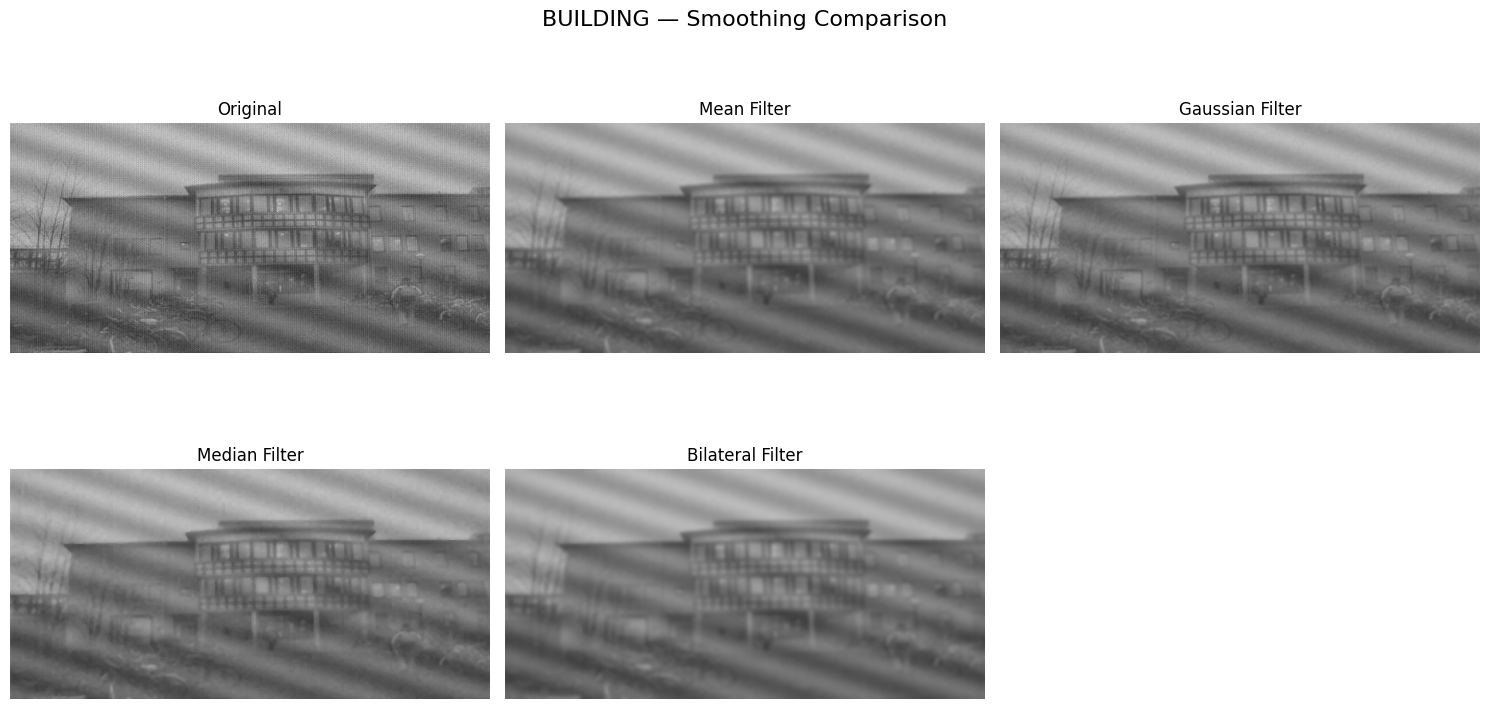

Saved comparison: OEP9_Results\building_smoothing_comparison.png


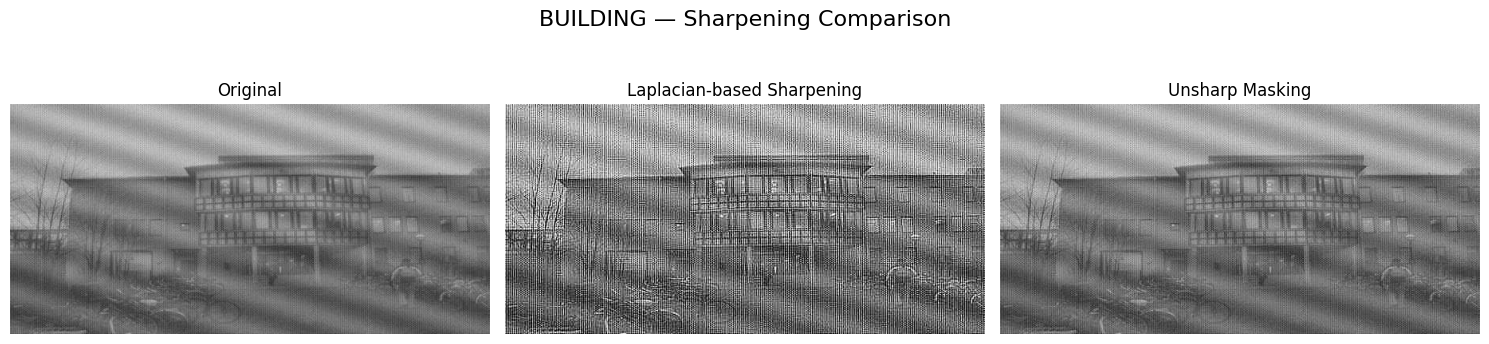

Saved comparison: OEP9_Results\building_sharpening_comparison.png

Processing: motion (motion.jpg)
Saved: OEP9_Results\motion_original.png
Saved: OEP9_Results\motion_mean.png
Saved: OEP9_Results\motion_gaussian.png
Saved: OEP9_Results\motion_median.png
Saved: OEP9_Results\motion_bilateral.png
Saved: OEP9_Results\motion_laplacian_sharpened.png
Saved: OEP9_Results\motion_unsharp.png


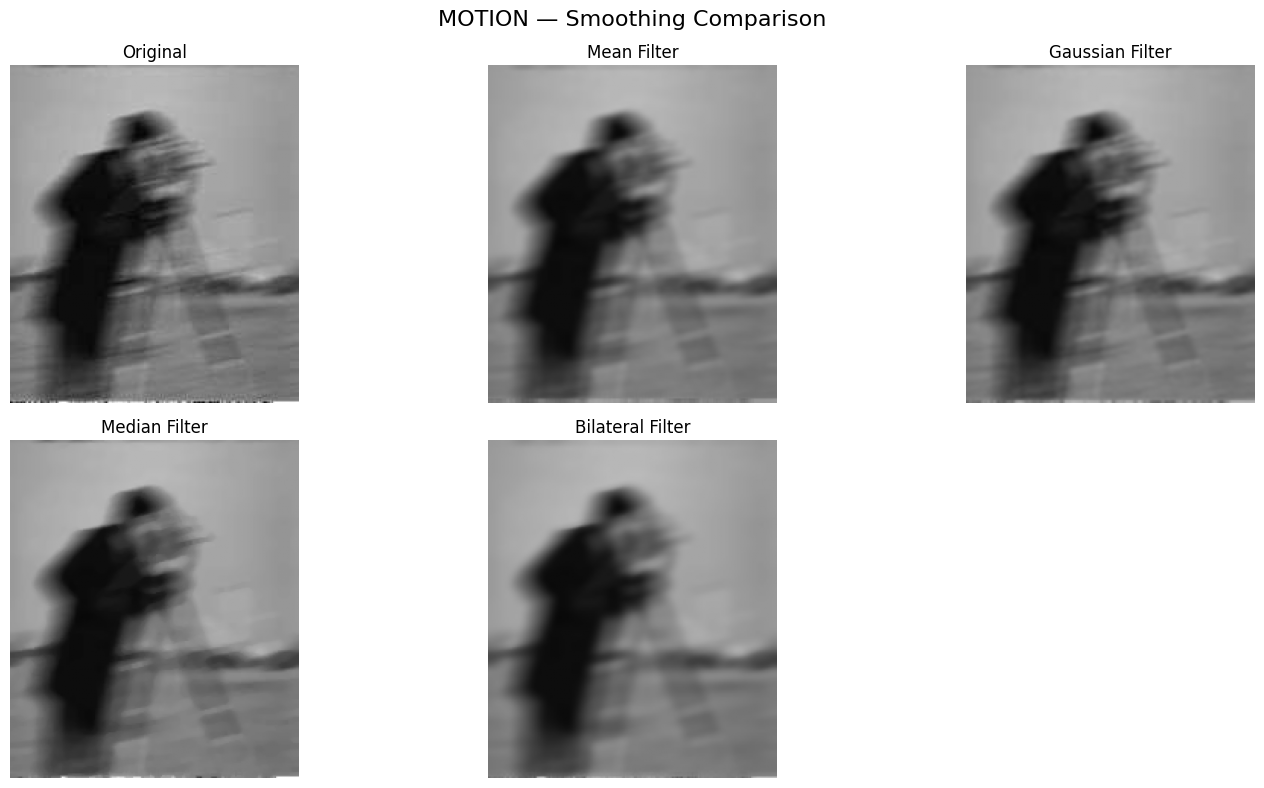

Saved comparison: OEP9_Results\motion_smoothing_comparison.png


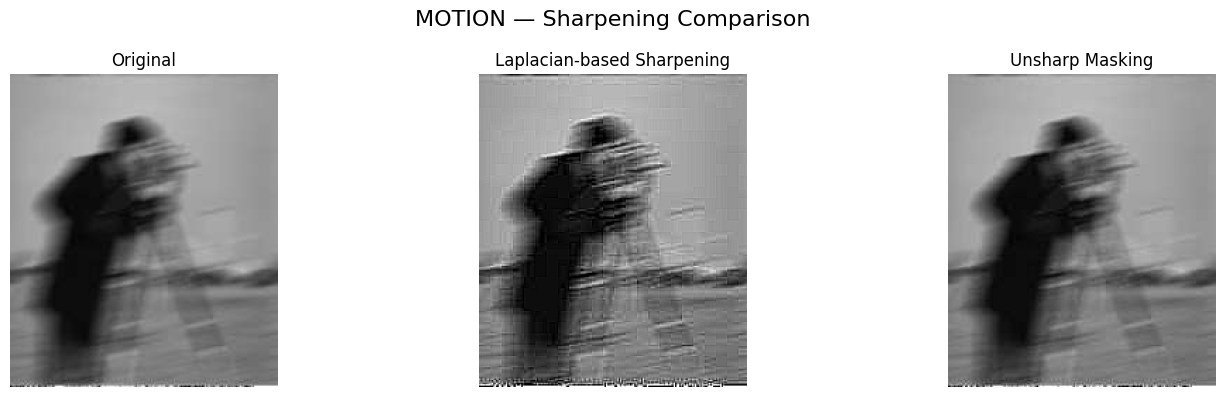

Saved comparison: OEP9_Results\motion_sharpening_comparison.png

Processing summary
Successfully processed: ['face', 'xray', 'city', 'building', 'motion']
All five images processed successfully.


In [ ]:
all_results = {}
errors = {}

for image_key, image_filename in IMAGE_FILES.items():
    try:
        all_results[image_key] = process_image(image_key, image_filename)
    except Exception as error:
        errors[image_key] = str(error)
        print(f"ERROR while processing {image_filename}: {error}")

print("\nProcessing summary")
print("Successfully processed:", list(all_results.keys()))
if errors:
    print("Images with errors:", errors)
else:
    print("All five images processed successfully.")

In [ ]:
saved_files = sorted(OUTPUT_DIR.glob("*"))
print(f"Output folder contains {len(saved_files)} files:")
for file_path in saved_files:
    print(file_path.name)

Output folder contains 45 files:
building_bilateral.png
building_gaussian.png
building_laplacian_sharpened.png
building_mean.png
building_median.png
building_original.png
building_sharpening_comparison.png
building_smoothing_comparison.png
building_unsharp.png
city_bilateral.png
city_gaussian.png
city_laplacian_sharpened.png
city_mean.png
city_median.png
city_original.png
city_sharpening_comparison.png
city_smoothing_comparison.png
city_unsharp.png
face_bilateral.png
face_gaussian.png
face_laplacian_sharpened.png
face_mean.png
face_median.png
face_original.png
face_sharpening_comparison.png
face_smoothing_comparison.png
face_unsharp.png
motion_bilateral.png
motion_gaussian.png
motion_laplacian_sharpened.png
motion_mean.png
motion_median.png
motion_original.png
motion_sharpening_comparison.png
motion_smoothing_comparison.png
motion_unsharp.png
xray_bilateral.png
xray_gaussian.png
xray_laplacian_sharpened.png
xray_mean.png
xray_median.png
xray_original.png
xray_sharpening_comparison.png


In [ ]:
import zipfile

zip_path = Path("OEP9_Results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in OUTPUT_DIR.glob("*"):
        if file_path.is_file():
            archive.write(file_path, arcname=f"{OUTPUT_DIR.name}/{file_path.name}")

print("Created ZIP:", zip_path.resolve())
print("Find OEP9_Results.zip in the VS Code Explorer.")

Created ZIP: C:\Users\shash\OneDrive\Desktop\SEMESTER05\DSIP(01CT0513)\Python DSIP\OPE 9\OEP9_Results.zip
Find OEP9_Results.zip in the VS Code Explorer.
